The code below imports the four functions from the load.py file and reads the raw csv file with every column as a text so sensor IDs aren't rounded to sig figures. 

Moreover, the function skips the repeated uploads and unpacks each jsondata cell into seperate readings such as sensor, variable, unit, value and measurement time as well as dropping readings the sensor flagged with error.

In [1]:
from mma3001_project.load import parse_env_csv, sensor_summary, clean_sensor_frame, cleaning_report
long = parse_env_csv("../data/raw/5EnvSensor_MayToDec2024_180kRows.csv")
long.shape

(430862, 5)

After processing the raw data, the code below builds one row per sensor to filter out working sensors against frozen sensors that re-sends the same reading repeatedly.

In [2]:
sensor_summary(long)

,n_uploads,n_readings,first,last,n_distinct_co2,unique_ratio,is_live
sensorid,,,,,,,
6012002000227,21363,1,2023-12-11 05:07:53+00:00,2023-12-11 05:07:53+00:00,1,0.000,False
6012002000241,58908,2,2023-12-11 05:52:45+00:00,2025-05-19 13:08:04+00:00,2,0.000,False
6012002000326,58909,29039,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,245,0.493,True
6012002000777,10926,1,2023-05-05 22:42:45+00:00,2023-05-05 22:42:45+00:00,1,0.000,False
6012002000869,29341,13800,2024-02-29 06:04:56+00:00,2024-06-13 17:45:44+00:00,222,0.470,True


Take readings for sensor 869 only as it is the sole working sensor that occupies an identified room, keeping the CO2, temperature and humidity variables. 

The readings are placed into a 10 minute grid 

In [3]:
clean = clean_sensor_frame(long, "6012002000869", end="2024-06-14")
clean.head()

,co2_ppm,temp_c,rh_pct
time_utc,,,
2024-02-29 06:00:00+00:00,465.0,24.3,56.0
2024-02-29 06:10:00+00:00,445.0,24.0,56.0
2024-02-29 06:20:00+00:00,NaN,NaN,NaN
2024-02-29 06:30:00+00:00,471.0,23.8,56.0
2024-02-29 06:40:00+00:00,457.0,23.8,56.0


Summarizing each column to verify all values are within ranges.

In [4]:
cleaning_report(clean)

,slots,missing,missing_pct,n_gaps,longest_gap,min,median,max
co2_ppm,15191.0,1391.0,9.2,1390.0,2.0,403.0,463.0,646.0
temp_c,15191.0,1391.0,9.2,1390.0,2.0,19.0,23.3,28.5
rh_pct,15191.0,1391.0,9.2,1390.0,2.0,26.0,45.0,75.0


Plotting data from one week to visualize a less noisy example of CO2 and temperature values over time, within the chosen week. 

From the graph, it can be seen that CO2 rises during each weekday as occupants arrive, falls overnight when it is likely empty and stays flat throughout the weekend to signal low/no activity, thus modelling a proposed occupancy pattern. Temperature jumps between 7-8am each morning including the weekend signal the HVAC switching on to a fixed schedule.
Small breaks in lines are missed readings.

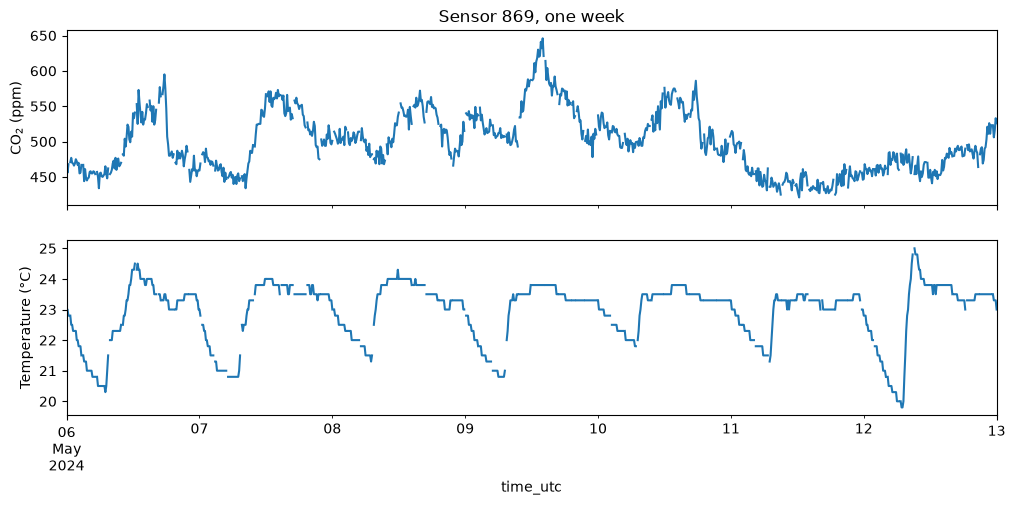

In [5]:
import matplotlib.pyplot as plt
wk = clean["2024-05-05T14:00Z":"2024-05-12T14:00Z"].tz_convert("Australia/Melbourne")
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
wk["co2_ppm"].plot(ax=axes[0], ylabel="CO$_2$ (ppm)", title="Sensor 869, one week")
wk["temp_c"].plot(ax=axes[1], ylabel="Temperature (°C)")
plt.show()

Saving the cleaned data into a data output folder with a name and exporting it as a csv file.

In [6]:
import os
os.makedirs("../data/processed", exist_ok=True)
clean.to_csv("../data/processed/sensor869_clean.csv")